In [1]:
import sys
sys.path.append("..")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from statsmodels.stats.multitest import multipletests

from src.db import read_sql_file
from src.stats import compare_arms, heterogeneity_test

In [2]:
seg = read_sql_file("12_segment_summary_stats.sql")
seg = seg.astype({
    "n": int, "segment_share": float, "visits": int, "conversions": int,
    "spend_mean": float, "spend_var": float,
})
seg.head(9)

,dimension,segment,arm,n,segment_share,visits,conversions,spend_mean,spend_var
0,area_type,rural,control,3139,0.1473,482,26,0.767136,107.066400
1,area_type,rural,mens,3243,0.1522,736,44,1.522636,308.463018
2,area_type,rural,womens,3181,0.1487,581,37,1.281977,224.752042
3,area_type,suburban,control,9625,0.4518,953,48,0.669442,156.301352
4,area_type,suburban,mens,9501,0.4459,1647,118,1.473290,345.865319
5,area_type,suburban,womens,9650,0.4512,1427,73,0.846613,188.605712
6,area_type,urban,control,8542,0.4009,827,48,0.592005,119.503256
7,area_type,urban,mens,8563,0.4019,1511,105,1.328512,283.813627
8,area_type,urban,womens,8556,0.4001,1230,79,1.261141,274.824770


In [ ]:
rows = []
for (dimension, segment), group in seg.groupby(["dimension", "segment"]):
    summary = group.set_index("arm")
    for treatment in ["mens", "womens"]:
        result = compare_arms(summary, treatment, "control")
        result.insert(0, "dimension", dimension)
        result.insert(1, "segment", segment)
        rows.append(result)

seg_results = pd.concat(rows, ignore_index=True)

# Effects on the primary metric, one row per segment and email
seg_results[seg_results["metric"] == "visit"][
    ["dimension", "segment", "comparison", "diff", "ci_low", "ci_high", "p_value"]
].style.format({"diff": "{:.3f}", "ci_low": "{:.3f}", "ci_high": "{:.3f}", "p_value": "{:.2e}"})

,dimension,segment,comparison,diff,ci_low,ci_high,p_value
2,area_type,rural,mens vs control,0.756,0.051,1.460,3.56e-02
5,area_type,rural,womens vs control,0.515,-0.120,1.149,1.12e-01
8,area_type,suburban,mens vs control,0.804,0.354,1.254,4.60e-04
11,area_type,suburban,womens vs control,0.177,-0.194,0.548,3.49e-01
14,area_type,urban,mens vs control,0.737,0.311,1.162,6.95e-04
17,area_type,urban,womens vs control,0.669,0.248,1.090,1.84e-03
20,channel,multichannel,mens vs control,1.209,0.391,2.027,3.79e-03
23,channel,multichannel,womens vs control,1.158,0.259,2.056,1.16e-02
26,channel,phone,mens vs control,0.564,0.161,0.967,6.08e-03
29,channel,phone,womens vs control,0.232,-0.119,0.584,1.95e-01


In [7]:
het_rows = []
for (dimension, comparison, metric), group in seg_results.groupby(
    ["dimension", "comparison", "metric"]
):
    test = heterogeneity_test(group["diff"], group["se"])
    het_rows.append({"dimension": dimension, "comparison": comparison, "metric": metric, **test})

het = pd.DataFrame(het_rows)

# Primary hypothesis: past purchase category. Everything else is exploratory -> FDR (Benjamini-Hochberg)
het["analysis"] = np.where(het["dimension"] == "past_purchase_category", "primary", "exploratory")

exploratory = het["analysis"] == "exploratory"
_, p_bh, _, _ = multipletests(het.loc[exploratory, "p_value"], alpha=0.05, method="fdr_bh")
het.loc[exploratory, "p_value_bh"] = p_bh

het.sort_values(["analysis", "p_value"], ascending=[False, True]).style.format({
    "pooled_effect": "{:.4f}", "q_stat": "{:.2f}", "p_value": "{:.2e}", "p_value_bh": "{:.2e}",
})

,dimension,comparison,metric,pooled_effect,q_stat,df,p_value,analysis,p_value_bh
23,past_purchase_category,womens vs control,visit,0.0415,97.35,2,7.26e-22,primary,nan
20,past_purchase_category,mens vs control,visit,0.0742,23.25,2,8.95e-06,primary,nan
21,past_purchase_category,womens vs control,conversion,0.0027,7.85,2,1.98e-02,primary,nan
18,past_purchase_category,mens vs control,conversion,0.0063,5.23,2,7.31e-02,primary,nan
19,past_purchase_category,mens vs control,spend,0.6885,2.96,2,2.28e-01,primary,nan
22,past_purchase_category,womens vs control,spend,0.4648,2.14,2,3.43e-01,primary,nan
15,customer_type,womens vs control,conversion,0.0034,6.95,1,8.36e-03,exploratory,1.50e-01
16,customer_type,womens vs control,spend,0.4729,5.62,1,1.77e-02,exploratory,1.60e-01
17,customer_type,womens vs control,visit,0.0462,2.54,1,1.11e-01,exploratory,4.83e-01
5,area_type,womens vs control,visit,0.0457,3.63,2,1.63e-01,exploratory,4.83e-01


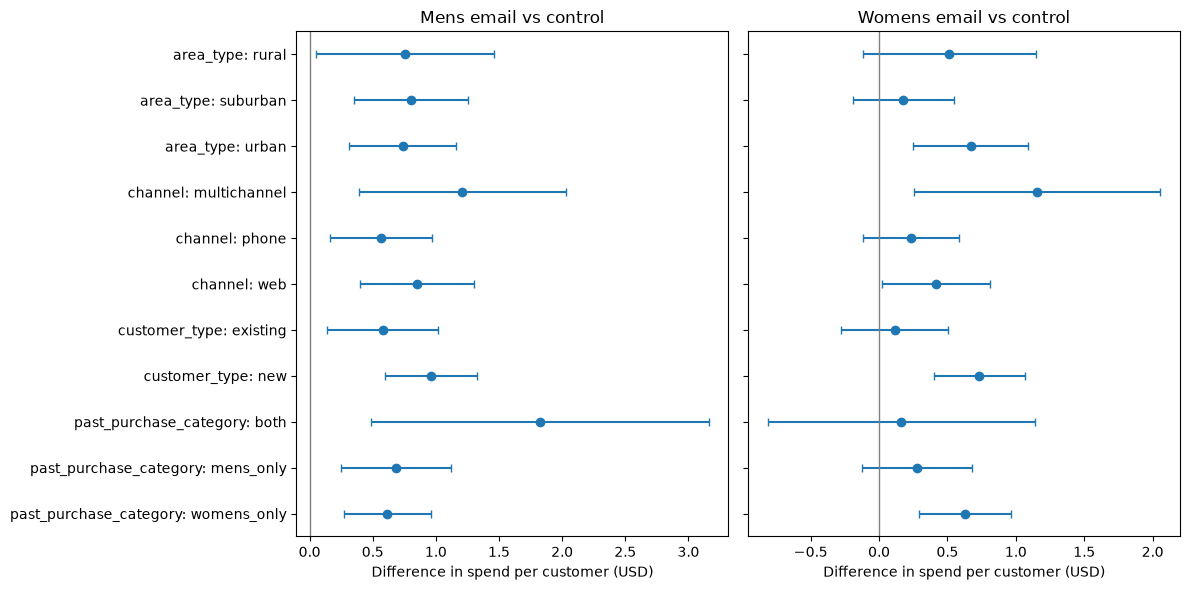

In [8]:
plot_df = seg_results[seg_results["metric"] == "spend"]

fig, axes = plt.subplots(1, 2, figsize=(12, 6), sharey=True)
for ax, treatment in zip(axes, ["mens", "womens"]):
    d = plot_df[plot_df["comparison"] == f"{treatment} vs control"].reset_index(drop=True)
    y = np.arange(len(d))
    ax.errorbar(
        d["diff"], y,
        xerr=[d["diff"] - d["ci_low"], d["ci_high"] - d["diff"]],
        fmt="o", capsize=3,
    )
    ax.axvline(0, color="grey", linewidth=1)
    ax.set_yticks(y)
    ax.set_yticklabels(d["dimension"] + ": " + d["segment"])
    ax.set_title(f"{treatment.capitalize()} email vs control")
    ax.set_xlabel("Difference in spend per customer (USD)")

axes[0].invert_yaxis()  # list segments from top to bottom
plt.tight_layout()
fig.savefig("../reports/figures/segment_effects_spend.png", dpi=150)
plt.show()

## Heterogeneous treatment effects

Segments are defined only by pre-experiment attributes. Heterogeneity is tested with Cochran's Q.
Past purchase category is the primary hypothesis; other dimensions are exploratory and FDR-adjusted (Benjamini-Hochberg).

- **Mens email:** increases spend in every segment examined (all 95% CIs above zero), including customers
  who previously bought only women's merchandise. No dimension shows significant heterogeneity in its
  spend effect (Q-test p ≥ 0.19). It is a robust default for all customers.
- **Womens email:** its spend effect appears concentrated among customers who previously bought only
  women's merchandise (+$0.63, 95% CI [0.30, 0.97]) and among new customers. However, the Q-test does not
  detect significant heterogeneity in spend (p = 0.34 for past purchase category), so these differences
  between segments may be noise.
- **Visits:** the effect of both emails on visit rate varies strongly by past purchase category
  (Q-test p < 0.001, robust to Holm correction across the 6 primary tests).
- **Exploratory:** the womens email appears more effective for new than for existing customers
  (raw p = 0.008 for conversion, 0.018 for spend), but this does not survive FDR correction
  (adjusted p ≥ 0.15). It should be treated as a hypothesis for a future experiment, not a finding.
- **Caveat:** small segments (e.g. customers who bought both categories, about 2,100 per arm) have wide confidence intervals.